# Foundations 4: Polynomials

*Learning path: foundations, part 4 of 9.* [Index](README.md) · Previous: [Functions and graphs](03-functions-and-graphs.ipynb) · Next: [Trigonometry](05-trigonometry.ipynb)

Polynomials are sums of powers of $x$ with number coefficients, like $2x^3 - 5x + 1$. They are the simplest functions
there are, yet they approximate almost every other function. You will learn

* degree, coefficients and the shape of a polynomial's graph,
* roots and the **factor theorem**: every root gives a factor,
* the **multiplicity** of a root and how it shows in the graph,
* long division of polynomials,
* how roots and coefficients are related (Vieta's formulas),
* that every polynomial of degree $n$ has exactly $n$ roots, if you count complex ones,
* how to fit a polynomial through given points.

## 1. Degree and coefficients

A polynomial of degree $n$ is

$$p(x) = a_n x^n + a_{n-1}x^{n-1} + \cdots + a_1 x + a_0, \qquad a_n \neq 0.$$

The numbers $a_k$ are its **coefficients**. `degree(p, x)` gives $n$ and `coeff(p, x, k)` gives $a_k$:

In [1]:
p = (x - 1)*(x + 2)*(2*x - 3);
expand(p)
degree(p, x)
coeff(p, x, 3)
coeff(p, x, 0)

2*x^3-x^2-7*x+6

> `expand`: Multiplies out products and powers.

3

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

2

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

6

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

The **leading coefficient** $a_n = 2$ and the degree decide what happens far away from the origin: for large $|x|$ the
term $2x^3$ is much bigger than all the others together, so the graph rises to the right and falls to the left. The
**constant term** $a_0 = p(0) = 6$ is where the graph crosses the vertical axis.

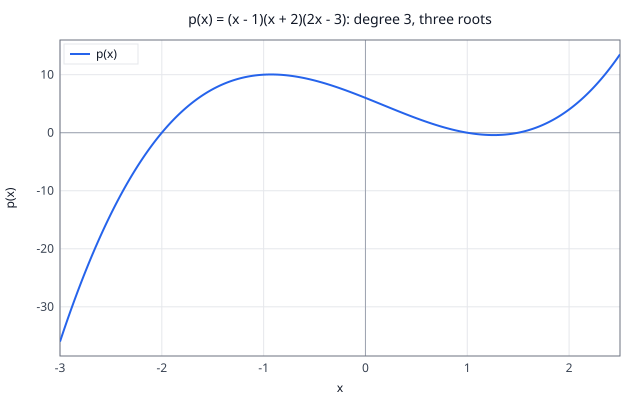

> `title`: A copy of plot p with a title or axis labels.

In [2]:
labels(title(legend(plot(p, x, -3, 2.5), "p(x)"), "p(x) = (x - 1)(x + 2)(2x - 3): degree 3, three roots"), "x", "p(x)")

The axes: $x$ runs from $-3$ to $2.5$ horizontally, and the height is $p(x)$. The curve crosses the horizontal axis at
the three **roots** $x = -2$, $x = 1$ and $x = 3/2$, and crosses the vertical axis at $p(0) = 6$.

## 2. Roots and factors

A **root** (or zero) of $p$ is a number $r$ with $p(r) = 0$. The **factor theorem** says:

> $r$ is a root of $p$ exactly when $(x - r)$ is a factor of $p$.

So finding roots and factoring are the same problem. `solve` finds the roots, `factor` the factors:

In [3]:
q = x^3 - 6*x^2 + 11*x - 6;
solve(q, x)
factor(q)

1	2	3

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

(x-3)*(x-2)*(x-1)

> `factor`: Factors a polynomial with rational coefficients over the integers, in any variables: (a*x + b)*(c*x + d) comes back from its expanded form.

How does one find such roots by hand? The **rational root test**: if a polynomial with whole-number coefficients has
a fraction $r = a/b$ (in lowest terms) as a root, then $a$ divides the constant term and $b$ divides the leading
coefficient. For $q$ the candidates are $\pm 1, \pm 2, \pm 3, \pm 6$. Try them all at once with `table`, which
computes an expression for a list of values, here $q(r)$ for each candidate $r$:

In [4]:
table(subs(q, x, r), r, [1, -1, 2, -2, 3, -3, 6, -6])

0	-24	0	-60	0	-120	60	-504

> `table`: A row with expr for each k; when expr is itself a row, the rows stack into a matrix.

The values are 0 for $r = 1, 2, 3$: those are the roots.

### Long division

Once you know one root, divide it out to get a smaller polynomial. `polydiv(p, d, x)` divides $p$ by $d$ and returns
`[quotient, remainder]`, with $p = \text{quotient}\cdot d + \text{remainder}$:

In [5]:
polydiv(q, x - 1, x)

x^2-5*x+6	0

> `polydiv`: Long division of polynomials in x: [quotient, remainder] with p = quotient*q + remainder and the remainder of lower degree than q.

The remainder is 0 because 1 is a root. The quotient $x^2 - 5x + 6$ is a quadratic, which the quadratic formula
handles. Dividing by something that is not a factor leaves a remainder, and the **remainder theorem** says that the
remainder of dividing by $x - r$ is just $p(r)$:

In [6]:
polydiv(q, x - 5, x)
subs(q, x, 5)

x^2-x+6	24

> `polydiv`: Long division of polynomials in x: [quotient, remainder] with p = quotient*q + remainder and the remainder of lower degree than q.

24

> `subs`: Replaces the variable x by a value.

## 3. Multiplicity: crossing or touching

A root can appear more than once. In $(x-1)^2(x+2)$ the root 1 has **multiplicity** 2. At a root of even multiplicity
the graph touches the axis and turns back; at a root of odd multiplicity it crosses. A triple root crosses while
flattening out:

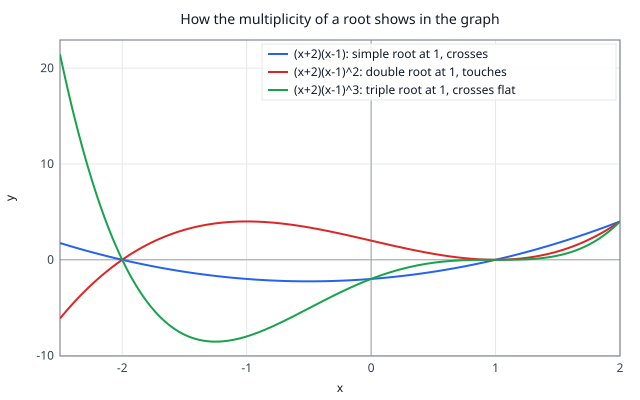

> `title`: A copy of plot p with a title or axis labels.

In [7]:
a1 = (x + 2)*(x - 1);
a2 = (x + 2)*(x - 1)^2;
a3 = (x + 2)*(x - 1)^3;
p = plot(a1, a2, a3, x, -2.5, 2);
p = legend(p, "(x+2)(x-1): simple root at 1, crosses", "(x+2)(x-1)^2: double root at 1, touches", "(x+2)(x-1)^3: triple root at 1, crosses flat");
labels(title(p, "How the multiplicity of a root shows in the graph"), "x", "y")

All three curves cross at the simple root $x = -2$ and pass through $(1, 0)$, but in three different ways.

## 4. Roots and coefficients: Vieta's formulas

Multiply out $(x - r_1)(x - r_2)$ with symbolic roots $r_1, r_2$, and look at the coefficient of each power of $x$:

In [8]:
two = expand((x - r1)*(x - r2));
coeff(two, x, 1)
coeff(two, x, 0)
three = expand((x - r1)*(x - r2)*(x - r3));
coeff(three, x, 2)
coeff(three, x, 1)
coeff(three, x, 0)

-r1-r2

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

r1*r2

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

-r1-r2-r3

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

r1*r2+r1*r3+r2*r3

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

-r1*r2*r3

> `coeff`: Coefficient of x^n in the polynomial p, and the degree of p in x.

The coefficients are built from the roots: for a monic quadratic $x^2 + bx + c$ the roots add up to $-b$ and
multiply to $c$; for a cubic $x^3 + bx^2 + cx + d$ the sum is $-b$, the sum of the products of pairs is $c$, and the
product is $-d$. These are **Vieta's
formulas** (1591). They let you check roots without computing them. For $q = x^3 - 6x^2 + 11x - 6$ the roots
$1, 2, 3$ add to $6$ and multiply to $6$. ✓

## 5. Every polynomial has as many roots as its degree

Some polynomials have no real roots at all: $x^2 + 1 > 0$ for every real $x$. Its roots are complex:

In [9]:
solve(x^2 + 1, x)

-i	i

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

The **fundamental theorem of algebra** (Gauss, 1799) says that a polynomial of degree $n$ always has exactly $n$
complex roots, counted with multiplicity. Above degree 4 there is in general no formula with roots (Abel, 1824), so
Galileo finds those roots numerically. Here are the five roots of $x^5 - x - 1$; only one is real:

In [10]:
solve(x^5 - x - 1, x)

1.1673039782614187	-0.7648844336005847-0.3524715460317262*i	-0.7648844336005847+0.3524715460317262*i	0.18123244446987535-1.0839541013177107*i	0.18123244446987535+1.0839541013177107*i

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

The complex roots come in pairs $a \pm bi$ (*conjugates*) whenever the coefficients are real. The
[complex numbers lesson](06-complex-numbers.ipynb) draws such roots in the plane.

## 6. A polynomial through given points

Through any two points there is exactly one line; through any three points (with different $x$) exactly one parabola.
To find the parabola $y = a x^2 + b x + c$ through $(0, 1)$, $(1, 0)$ and $(3, 4)$, write one equation per point and
solve for the coefficients:

In [11]:
y(x) := a*x^2 + b*x + c;
solve([y(0) == 1, y(1) == 0, y(3) == 4], [a, b, c])

1	-2	1

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

So $a = 1$, $b = -2$, $c = 1$, and the parabola is $x^2 - 2x + 1 = (x - 1)^2$. To check, draw it together with the
three points. The command `scatter(data, [x y])` draws points: `data` has one row per point, here $[x\ y]$, and
`[x y]` names the two columns (the first goes across, the second up):

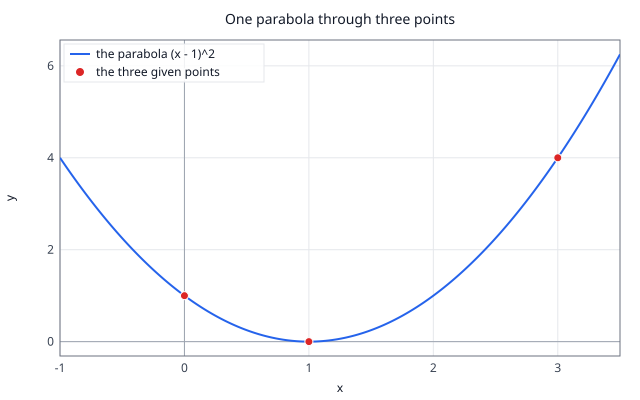

> `title`: A copy of plot p with a title or axis labels.

In [12]:
pts = [0 1; 1 0; 3 4];
fit = labels(plot((x - 1)^2, x, -1, 3.5), "x", "y");
p = show(fit, scatter(pts, [x y]));
title(legend(p, "the parabola (x - 1)^2", "the three given points"), "One parabola through three points")

## Summary

* Degree and leading coefficient decide the far-away shape; the constant term is $p(0)$.
* Factor theorem: $p(r) = 0 \iff (x - r)$ divides $p$. `solve` and `factor` are two views of the same thing.
* Rational root test, long division with `polydiv`, remainder theorem $\text{rem} = p(r)$.
* Even multiplicity touches, odd multiplicity crosses.
* Vieta: sums and products of roots are coefficients. Degree $n$ means $n$ complex roots.

**Try it:** find all roots of $x^4 - 5x^2 + 4$ by hand (hint: substitute $u = x^2$), then check with `factor`. Fit a
cubic through $(0, 0)$, $(1, 1)$, $(2, 0)$, $(3, 3)$.

Next: [Trigonometry](05-trigonometry.ipynb).

## Sources

1. F. Viète, *De aequationum recognitione et emendatione* (1591, printed 1615). Relations between roots and coefficients.
2. C. F. Gauss, *Demonstratio nova theorematis omnem functionem algebraicam rationalem integram unius variabilis in factores reales primi vel secundi gradus resolvi posse*, doctoral thesis, Helmstedt (1799). First proof of the fundamental theorem of algebra.
3. N. H. Abel, "Mémoire sur les équations algébriques où l'on démontre l'impossibilité de la résolution de l'équation générale du cinquième degré" (1824).